/tmp/ipykernel_56601/3746078422.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=label_names, y=label_counts.values, palette='Set2')


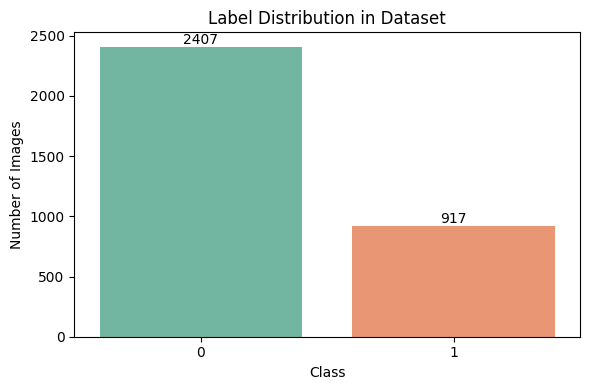

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
import torch

# ✅ Load your own image
your_image_path =r'/home/user/Desktop/oral_cancer/gdc_oral_cancer_dataset/oral-cancer-detection/data/original/20/image_1.jpeg'  # or use the uploaded file path
original_image = Image.open(your_image_path).convert('RGB')
img_np = np.array(original_image)

# ✅ Define LIME-compatible prediction function
def batch_predict(images):
    model.eval()
    batch = torch.stack([
        transform(Image.fromarray(img.astype(np.uint8))) for img in images
    ])
    batch = batch.to(device)
    with torch.no_grad():
        logits = model(batch)
        probs = torch.nn.functional.softmax(logits, dim=1)
    return probs.detach().cpu().numpy()

# ✅ Run LIME explainer
explainer = lime_image.LimeImageExplainer()

explanation = explainer.explain_instance(
    image=img_np,
    classifier_fn=batch_predict,
    top_labels=1,
    hide_color=0,
    num_samples=1000
)

# ✅ Get explanation mask: show helpful regions only
temp, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[0],
    positive_only=True,
    num_features=10,
    hide_rest=True  # 👈 hides unimportant areas
)

# ✅ Display result
plt.figure(figsize=(6, 6))
plt.imshow(mark_boundaries(temp / 255.0, mask))
plt.title("LIME - Custom Image Important Regions")
plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
df

,No.,Date of case registered,FLW username,Study setting,Age,Gender,Cigarette/Bidi,Smokeless tobacco,Areca nut,Alcohol,Able to open mouth,Lesion/patch,Provisional diagnosis,Risk,Specialist diagnosis,Specialist recommendation,Specialist notes,Image 1,Image 2,Image 3,Image 4,Image 5,Image 6,Image 7,Image 8,Image 9,Image 10,Image 11,Image 12,Image 13
0,1,14/12/2024,5,1,49,0,0,1,2,0,1,1,Homogenous Oral leukoplakia,0,1,Refer to hospital for additional investigation,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0
1,2,14/12/2024,1,1,44,1,1,1,1,1,1,1,Smokeless tobacco keratosis,0,1,Refer to hospital for additional investigation,0,https://site-9-production.arogyam-midas.iisc.a...,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0
2,3,16/12/2024,2,1,62,1,2,0,0,2,1,1,Homogenous Oral leukoplakia,0,1,Refer to hospital for additional investigation,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
3,4,16/12/2024,1,1,41,1,2,1,1,0,1,0,Oral cavity normal,0,0,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0
4,5,16/12/2024,5,1,43,1,0,0,2,0,1,0,Oral cavity normal,0,0,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0
5,6,16/12/2024,4,1,37,1,0,1,0,2,1,1,Speckled oral leukoplakia,1,1,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
6,7,16/12/2024,1,1,45,1,0,2,0,0,1,1,Oral cavity normal,0,0,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0,0
7,8,16/12/2024,2,1,51,1,0,2,0,0,1,1,Smokeless tobacco keratosis,0,1,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
9,10,16/12/2024,1,1,48,1,1,1,0,0,1,1,Oral cavity normal,0,0,Advice to quit the habit,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
10,11,16/12/2024,2,1,40,1,2,2,0,0,1,1,Smokeless tobacco keratosis,0,1,Refer to hospital for additional investigation,0,https://site-9-production.arogyam-midas.iisc.a...,https://site-9-production.arogyam-midas.iisc.a...,0,0,0,0,0,0,0,0,0,0,0
